# ПР-9. Метод опорных векторов: граница решения и прогноз оттока

Два набора данных:

- `make_moons`, 300 точек с двумя признаками. На нём видно, как ядро и параметры `C` и `gamma` меняют границу решения.
- `o_churn_synthetic.csv` из ПР-8, 3000 абонентов, целевой признак `churn`. Датасет синтетический, это не данные реального оператора. На нём подбираю параметры и сравниваю SVM с моделями из ПР-7 и ПР-8.

Разбиение оттока то же, что в ПР-8: 80/20, стратификация по `churn`, `random_state=42`. Поэтому числа логистической регрессии и XGBoost здесь совпадают с ПР-8. У случайного леса ROC-AUC 0.756 против 0.752 в ПР-8: там я отмечал, что числа леса менялись от запуска к запуску.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

DATA_PATH = "../data/o_churn_synthetic.csv"

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

CAT = ["region", "tariff"]
NUM = [c for c in X.columns if c not in CAT]

print("train:", X_train.shape, " test:", X_test.shape)
print("доля ушедших в train и test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("scikit-learn", sklearn.__version__)

train: (2400, 11)  test: (600, 11)
доля ушедших в train и test: 0.371 0.372
scikit-learn 1.9.1


## Веха 9.1. Линейное ядро и RBF на двумерных данных

`make_moons` даёт два полумесяца, которые заходят друг в друга. Прямой линией их не разделить.
Признаки масштабирую через `StandardScaler` внутри пайплайна, как и на основных данных.
Функция `plot_boundary` закрашивает области двух классов, рисует границу (сплошная линия) и края зазора (пунктир), а опорные векторы обводит кружками.

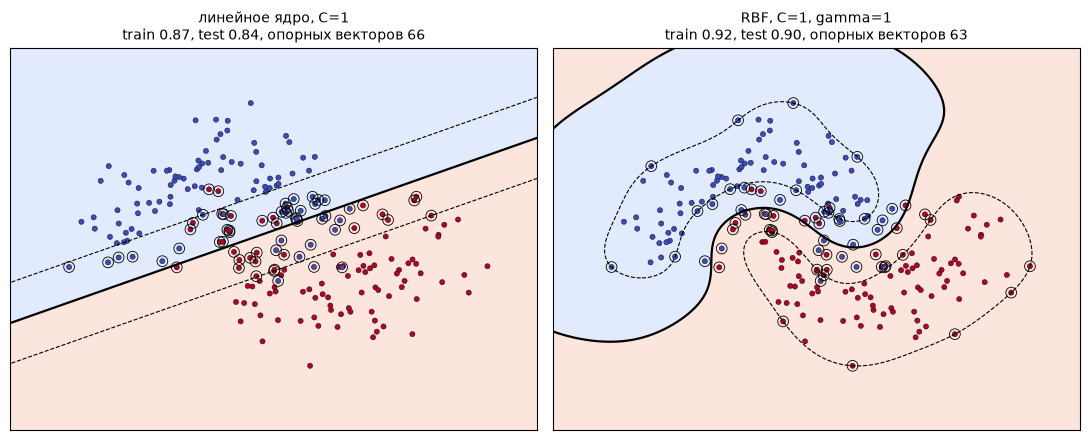

In [2]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=42)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    Xm, ym, test_size=0.3, stratify=ym, random_state=42)

xx, yy = np.meshgrid(np.linspace(-2.2, 3.2, 300), np.linspace(-1.7, 2.2, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]
moons_rows = []


def plot_boundary(ax, model, title):
    """Обучает пайплайн на Xm_tr, рисует границу решения и подписывает точность."""
    model.fit(Xm_tr, ym_tr)
    z = model.decision_function(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, z > 0, alpha=0.25, cmap="coolwarm")
    ax.contour(xx, yy, z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[0.8, 1.6, 0.8])
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap="coolwarm", s=14,
               edgecolors="k", linewidths=0.3)
    sv = model[0].inverse_transform(model[-1].support_vectors_)
    ax.scatter(sv[:, 0], sv[:, 1], s=60, facecolors="none", edgecolors="k", linewidths=0.6)
    acc_tr, acc_te = model.score(Xm_tr, ym_tr), model.score(Xm_te, ym_te)
    ax.set_title(f"{title}\ntrain {acc_tr:.2f}, test {acc_te:.2f}, опорных векторов {len(sv)}",
                 fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    moons_rows.append({"Модель": title, "Accuracy train": acc_tr,
                       "Accuracy test": acc_te, "Опорных векторов": len(sv)})


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_boundary(axes[0], make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)),
              "линейное ядро, C=1")
plot_boundary(axes[1], make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma=1)),
              "RBF, C=1, gamma=1")
plt.tight_layout()
plt.show()

**Какое ядро лучше разделило данные?** RBF. Линейное ядро может провести только прямую, поэтому концы полумесяцев попадают на чужую сторону: точность на test 0.844. Ядро RBF строит изогнутую границу, которая повторяет форму полумесяцев: точность на test 0.900.
Причина в форме данных: классы разделимы, но не прямой. RBF неявно переводит точки в пространство, где разделяющая поверхность может быть кривой.

## Веха 9.2. Как C и gamma меняют границу

`C` - штраф за ошибки на обучении. Малое `C` разрешает ошибки ради широкого зазора и простой границы, большое `C` старается не ошибаться ни на одной точке.
`gamma` - радиус влияния одной точки в ядре RBF. Малое `gamma` - каждая точка влияет далеко, граница гладкая. Большое `gamma` - влияние только рядом с точкой, граница огибает отдельные объекты.

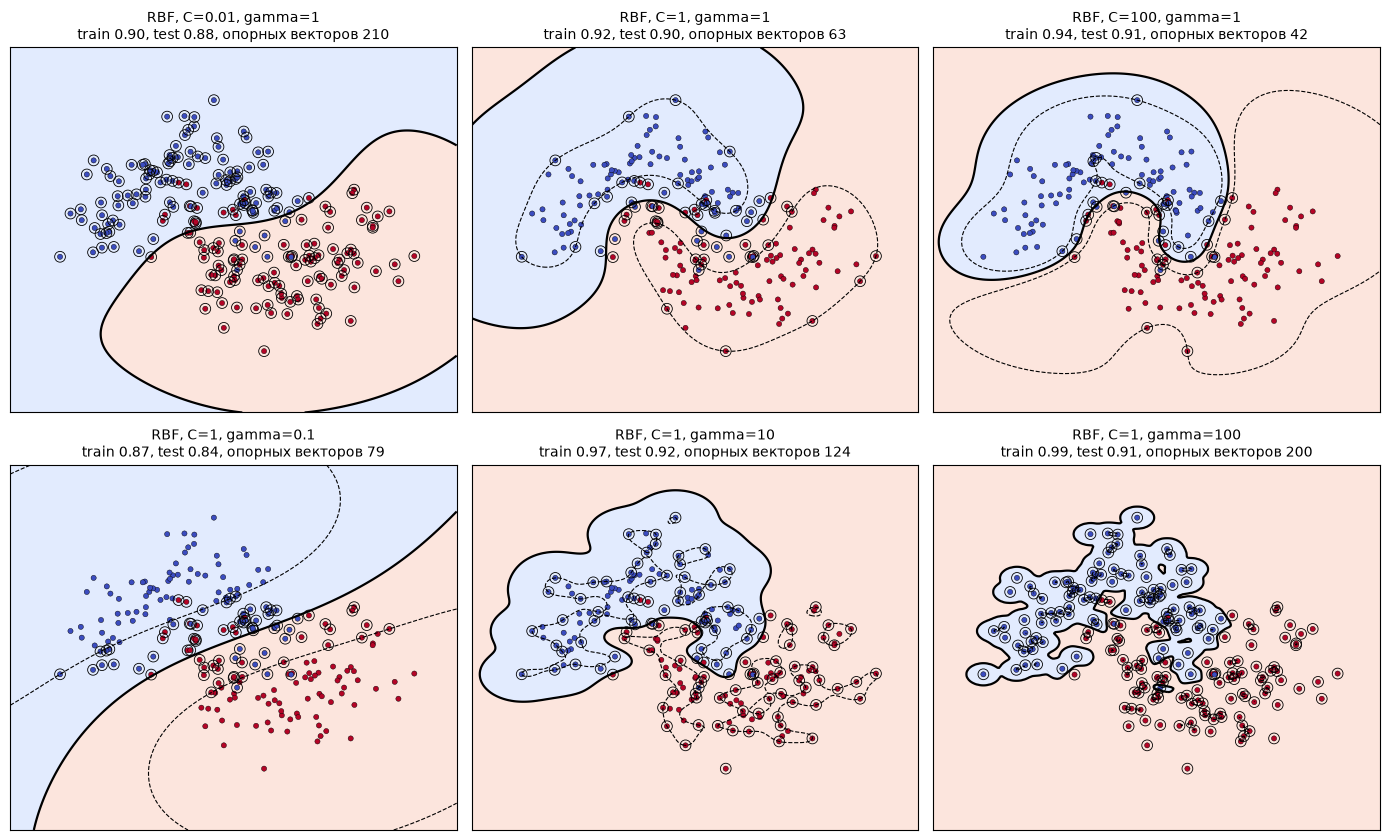

,Accuracy train,Accuracy test,Опорных векторов
Модель,,,
"линейное ядро, C=1",0.871,0.844,66
"RBF, C=1, gamma=1",0.924,0.900,63
"RBF, C=0.01, gamma=1",0.895,0.878,210
"RBF, C=100, gamma=1",0.943,0.911,42
"RBF, C=1, gamma=0.1",0.867,0.844,79
"RBF, C=1, gamma=10",0.967,0.922,124
"RBF, C=1, gamma=100",0.986,0.911,200


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, C in zip(axes[0], [0.01, 1, 100]):
    plot_boundary(ax, make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma=1)),
                  f"RBF, C={C}, gamma=1")
for ax, gamma in zip(axes[1], [0.1, 10, 100]):
    plot_boundary(ax, make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma=gamma)),
                  f"RBF, C=1, gamma={gamma}")
plt.tight_layout()
plt.show()

pd.DataFrame(moons_rows).drop_duplicates("Модель").set_index("Модель").round(3)

**Влияние C (верхний ряд).** При `C=0.01` штраф за ошибки маленький: граница гладкая, похожа на одну дугу, зазор широкий, и опорными векторами становятся все 210 обучающих точек. Точность на test 0.878. При `C=1` граница повторяет форму полумесяцев, опорных векторов 63, test 0.900. При `C=100` модель старается не ошибаться ни на одной точке: граница сильнее изгибается на стыке полумесяцев, опорных векторов 42, train 0.943. На test здесь 0.911, то есть большое `C` пока не навредило, но разрыв train/test вырос с 0.024 (`C=1`) до 0.032.

**Влияние gamma (нижний ряд).** При `gamma=0.1` каждая точка влияет далеко, граница почти прямая, и результат как у линейного ядра (test 0.844). При `gamma=10` граница плотно обходит синий полумесяц: train 0.967, test 0.922. При `gamma=100` синий класс превратился в островки вокруг отдельных обучающих точек, граница «обволакивает» объекты: train 0.986, test упал до 0.911, опорными стали 200 из 210 точек. Это переобучение: модель запоминает точки, а не форму классов. Всё за пределами островков считается красным классом, поэтому новая синяя точка чуть в стороне от обучающих получит неправильный ответ.

## Веха 9.3. Зачем масштабировать признаки

SVM ищет зазор по расстоянию между точками. Если признаки в разных единицах, расстояние определяет признак с самым большим разбросом.
Посмотрим на разброс числовых признаков оттока:

In [4]:
X_train[NUM].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
tenure_months,27.57,19.58,1.0,120.00
monthly_charge_som,471.08,191.43,150.0,856.00
internet_gb,16.24,12.75,0.2,117.80
support_calls_3m,1.16,1.10,0.0,6.00
autopay,0.35,0.48,0.0,1.00
days_since_topup,11.76,11.70,0.0,90.00
topups_3m,7.69,1.65,0.0,12.00
dropped_calls_pct,2.20,1.09,0.0,6.83
balance_som,80.30,47.18,0.0,226.00


Сравниваю одну и ту же модель `SVC(kernel="rbf")` с масштабированием и без. Качество считаю 5-кратной кросс-валидацией на train (ROC-AUC), test не трогаю.
Препроцессор стоит внутри пайплайна, поэтому в каждом фолде `StandardScaler` обучается только на обучающей части фолда. Так нет утечки.

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score


def make_prep(scale=True):
    """One-hot для категорий, числовые признаки масштабируются (или нет)."""
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), CAT)],
        remainder=StandardScaler() if scale else "passthrough")


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for scale in [False, True]:
    pipe = make_pipeline(make_prep(scale), SVC(kernel="rbf"))
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    label = "со StandardScaler" if scale else "без масштабирования"
    print(f"{label:<22} ROC-AUC CV = {scores.mean():.3f} ± {scores.std():.3f}")

без масштабирования    ROC-AUC CV = 0.679 ± 0.014


со StandardScaler      ROC-AUC CV = 0.747 ± 0.021


**Вывод.** Без масштабирования ROC-AUC 0.679, со `StandardScaler` 0.747. Разница 0.07, это в несколько раз больше разброса между фолдами (0.014-0.021). Без масштабирования расстояние между абонентами почти целиком определяют `monthly_charge_som` (std 191) и `balance_som` (std 47), а `support_calls_3m` и `dropped_calls_pct` (std около 1) почти не влияют, хотя по смыслу они важны для оттока. Модель формально обучается, но результат зависит от единиц измерения, а не от данных.
Дальше все SVM-модели обучаются только в пайплайне с `StandardScaler`.

## Веха 9.4. Сеточный поиск по C и gamma для RBF

Перебираю 6 значений `C` и 5 значений `gamma` с шагом в 10 раз, всего 30 комбинаций. Каждую проверяю 5-кратной стратифицированной кросс-валидацией на train, метрика ROC-AUC (как в ПР-7 и ПР-8). Test в подборе не участвует.
`return_train_score=True` сохраняет качество и на обучающих фолдах, чтобы было видно переобучение.

In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {"svc__C": [0.01, 0.1, 1, 10, 100, 1000],
              "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1]}
search_rbf = GridSearchCV(make_pipeline(make_prep(), SVC(kernel="rbf")), param_grid,
                          cv=cv, scoring="roc_auc", return_train_score=True)
t0 = time.perf_counter()
search_rbf.fit(X_train, y_train)
grid_sec = time.perf_counter() - t0

n_comb = len(param_grid["svc__C"]) * len(param_grid["svc__gamma"])
print(f"перебор {n_comb} комбинаций x 5 фолдов = {n_comb * 5} обучений, {grid_sec:.1f} с")
print("лучшие параметры:", search_rbf.best_params_)
print("ROC-AUC на кросс-валидации:", round(search_rbf.best_score_, 3))

перебор 30 комбинаций x 5 фолдов = 150 обучений, 20.6 с
лучшие параметры: {'svc__C': 100, 'svc__gamma': 0.0001}
ROC-AUC на кросс-валидации: 0.777


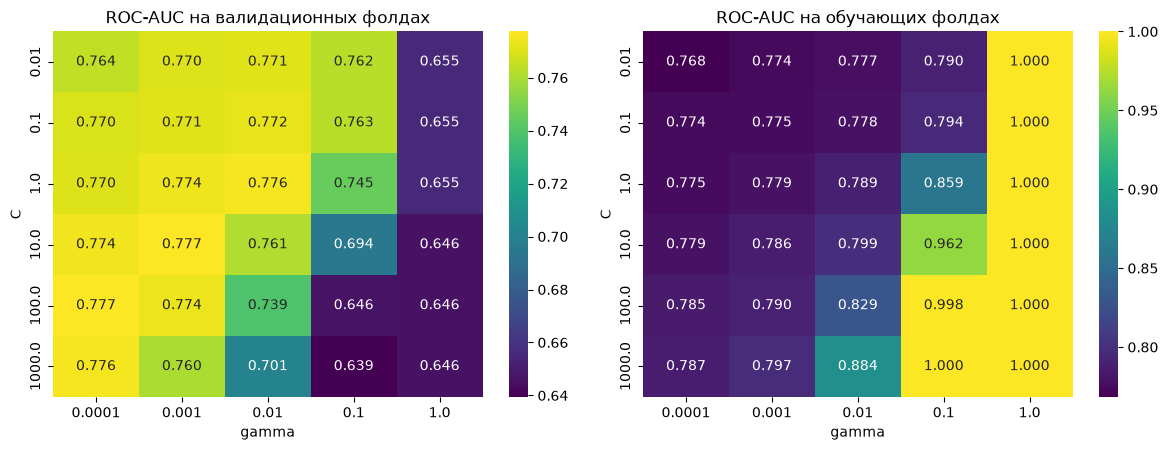

In [7]:
res = pd.DataFrame(search_rbf.cv_results_)
heat_cv = res.pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
heat_tr = res.pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_train_score")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(heat_cv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("ROC-AUC на валидационных фолдах")
sns.heatmap(heat_tr, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("ROC-AUC на обучающих фолдах")
for ax in axes:
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
plt.tight_layout()
plt.show()

**Закономерность.** 

- При `gamma=1` на обучающих фолдах ROC-AUC 1.000 при любом `C`, а на валидации всего 0.646-0.655. Модель запомнила train, как граница с островками на `make_moons` в вехе 9.2.
- При большом `C` вместе с большим `gamma` то же самое: `C=1000`, `gamma=0.1` дают 1.000 на обучающих фолдах и 0.639 на валидации.
- Лучшие значения (0.774-0.777) идут по диагонали: чем меньше `gamma`, тем большее `C` нужно. Малое `gamma` делает границу плавной, большое `C` не даёт ей стать слишком простой, и эти эффекты компенсируют друг друга.
- Лучшая клетка `C=100`, `gamma=0.0001` (0.777), но соседние клетки диагонали отличаются меньше чем на 0.003. Это меньше разброса между фолдами (около 0.014, см. веху 9.5), так что выбор внутри диагонали в пределах шума.
- Лучшее `gamma` оказалось на краю сетки, но расширять её дальше смысла нет: при `gamma`, стремящемся к нулю, ядро RBF становится почти линейным, а линейное ядро я проверяю отдельно в вехе 9.5.

## Веха 9.5. Линейное ядро

Тот же поиск для `kernel="linear"`. У линейного ядра нет `gamma`, перебираю только `C`.

In [8]:
search_lin = GridSearchCV(make_pipeline(make_prep(), SVC(kernel="linear")),
                          {"svc__C": [0.001, 0.01, 0.1, 1, 10]},
                          cv=cv, scoring="roc_auc")
t0 = time.perf_counter()
search_lin.fit(X_train, y_train)
lin_grid_sec = time.perf_counter() - t0

lin_res = pd.DataFrame(search_lin.cv_results_)[["param_svc__C", "mean_test_score", "std_test_score"]]
print(f"перебор 5 значений C x 5 фолдов, {lin_grid_sec:.1f} с")
print("лучшее C:", search_lin.best_params_["svc__C"],
      " ROC-AUC на кросс-валидации:", round(search_lin.best_score_, 3))
lin_res.round(3)

перебор 5 значений C x 5 фолдов, 1.5 с
лучшее C: 0.01  ROC-AUC на кросс-валидации: 0.778


,param_svc__C,mean_test_score,std_test_score
0,0.001,0.770,0.014
1,0.010,0.778,0.014
2,0.100,0.776,0.014
3,1.000,0.775,0.014
4,10.000,0.775,0.014


**Вывод.** Лучшее `C=0.01`, ROC-AUC на кросс-валидации 0.778, столько же, сколько у лучшего RBF (0.777). При `C` от 0.01 до 10 качество почти не меняется (0.775-0.778) и падает только при `C=0.001` (0.770), где зазор слишком широкий. Перебор линейного ядра занял около 1.5 с, а RBF около 21 с.
Нелинейное ядро на этих данных ничего не даёт: граница между ушедшими и оставшимися абонентами близка к линейной. Это совпадает с ПР-8, где лучшей оказалась логистическая регрессия.

## Веха 9.6. Сравнение с моделями из ПР-7 и ПР-8

Все модели обучаются на одном и том же train и проверяются на одном test. Функция `fit_and_report` та же, что в ПР-8, только ROC-AUC для SVM считается по `decision_function`: у `SVC` без `probability=True` нет `predict_proba`, а для ROC-AUC нужна только упорядоченность объектов, вероятности не обязательны.

- логистическая регрессия - базовая модель из ПР-8;
- случайный лес из 100 деревьев - модель ПР-7, обученная на этих данных в ПР-8;
- XGBoost с параметрами, подобранными в ПР-8 (`learning_rate=0.05`, `max_depth=3`, 127 деревьев);
- SVM с линейным ядром и SVM с RBF с параметрами из вех 9.4 и 9.5.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from xgboost import XGBClassifier
import xgboost


def scores_for_auc(pipe, X_part):
    """Вероятность класса 1, а если её нет (SVC), то расстояние до границы."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X_part)[:, 1]
    return pipe.decision_function(X_part)


def fit_and_report(name, pipe):
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    sec = time.perf_counter() - t0
    return {"Модель": name,
            "F1 train": f1_score(y_train, pipe.predict(X_train)),
            "F1 test": f1_score(y_test, pipe.predict(X_test)),
            "ROC-AUC test": roc_auc_score(y_test, scores_for_auc(pipe, X_test)),
            "Время, с": sec}


best_C, best_gamma = search_rbf.best_params_["svc__C"], search_rbf.best_params_["svc__gamma"]
lin_C = search_lin.best_params_["svc__C"]
models = {
    "Логрегрессия (ПР-8)": make_pipeline(make_prep(), LogisticRegression(max_iter=1000)),
    "Случайный лес (ПР-7)": make_pipeline(make_prep(scale=False), RandomForestClassifier(
        n_estimators=100, random_state=42)),
    "XGBoost (ПР-8)": make_pipeline(make_prep(scale=False), XGBClassifier(
        n_estimators=127, learning_rate=0.05, max_depth=3, random_state=42)),
    f"SVM, линейное, C={lin_C}": make_pipeline(make_prep(), SVC(kernel="linear", C=lin_C)),
    f"SVM, RBF, C={best_C}, gamma={best_gamma}": make_pipeline(
        make_prep(), SVC(kernel="rbf", C=best_C, gamma=best_gamma)),
}
rows = [fit_and_report(name, pipe) for name, pipe in models.items()]
summary = pd.DataFrame(rows).set_index("Модель").round(3)
print("xgboost", xgboost.__version__)
summary

xgboost 3.4.1


,F1 train,F1 test,ROC-AUC test,"Время, с"
Модель,,,,
Логрегрессия (ПР-8),0.594,0.611,0.806,0.005
Случайный лес (ПР-7),1.000,0.552,0.756,0.140
XGBoost (ПР-8),0.645,0.586,0.792,0.091
"SVM, линейное, C=0.01",0.563,0.582,0.801,0.032
"SVM, RBF, C=100, gamma=0.0001",0.570,0.595,0.801,0.040


**Сравнение.** 

- Обе SVM на test почти одинаковые: ROC-AUC 0.801, F1 0.582 у линейного ядра и 0.595 у RBF. По ROC-AUC они лучше XGBoost (0.792) и случайного леса (0.756), но чуть хуже логистической регрессии (0.806, F1 0.611).
- SVM почти не переобучаются: F1 на train (0.563 и 0.570) даже ниже, чем на test, как у логрегрессии. У леса F1 на train 1.000.
- Одно обучение SVM занимает 0.03-0.04 с: быстрее леса и XGBoost, но в несколько раз медленнее логрегрессии. Время немного меняется от запуска к запуску.
- Разница ROC-AUC между SVM, логрегрессией и XGBoost 0.005-0.014 на тесте из 600 абонентов, это в пределах шума. Заметно хуже остальных только лес.

## Веха 9.7. Время обучения SVM

У `SVC` время обучения растёт быстрее, чем линейно с числом объектов: алгоритм работает с попарными расстояниями. Проверяю на части train: 25%, 50% и 100% строк, лучшие параметры RBF.

In [10]:
time_rows = []
for frac in [0.25, 0.5, 1.0]:
    n = int(len(X_train) * frac)
    pipe = make_pipeline(make_prep(), SVC(kernel="rbf", C=best_C, gamma=best_gamma))
    t0 = time.perf_counter()
    pipe.fit(X_train.iloc[:n], y_train.iloc[:n])
    time_rows.append({"Строк": n, "Время, с": time.perf_counter() - t0,
                      "Опорных векторов": len(pipe[-1].support_)})
pd.DataFrame(time_rows).set_index("Строк").round(3)

,"Время, с",Опорных векторов
Строк,,
600,0.005,407
1200,0.011,770
2400,0.039,1525


### Итог

Время обучения растёт быстрее объёма данных: при 600, 1200 и 2400 строках примерно 0.005, 0.012 и 0.04 с, то есть в 4 раза больше строк дают примерно в 8 раз больше времени. Опорными векторами стали 1525 из 2400 объектов (64%): классы сильно перекрываются, и модели приходится хранить большую часть обучающей выборки.

**Оправдан ли SVM на этих данных?** По качеству SVM на уровне лучших моделей: ROC-AUC 0.801 на test, рядом с логистической регрессией (0.806), выше XGBoost (0.792) и леса (0.756). Но ничего сверх логистической регрессии он не даёт:

- лучшее RBF-ядро выродилось почти в линейное (`gamma=0.0001`), а линейное ядро дало то же качество на кросс-валидации (0.778 против 0.777);
- логистическая регрессия обучается в несколько раз быстрее и сразу даёт вероятности, а `SVC` для вероятностей нужно дополнительное обучение с `probability=True`;
- подбор RBF занял около 21 с (150 обучений). На 2400 строках это немного, но с ростом данных время растёт быстрее, чем число строк.

Вывод: на этих данных SVM применять можно, но не нужно, ту же точность проще и быстрее даёт логистическая регрессия. SVM с RBF был бы оправдан, если бы граница между классами была нелинейной, как у `make_moons` в вехе 9.1 (там RBF поднял точность на test с 0.844 до 0.900), и данных было бы не больше нескольких десятков тысяч строк.